# 06 — Extra Trees (Extremely Randomised Trees)

**Algorithm:** ExtraTreesClassifier  
**Features:** TF-IDF (50K unigrams + bigrams)  
Extra Trees uses random thresholds at each feature split (instead of the best threshold), making it faster and often more regularised than Random Forest.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Model Training

In [3]:
from sklearn.ensemble import ExtraTreesClassifier
MODEL_NAME = 'Extra Trees'
model = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')

Training completed in 132.22s


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  Extra Trees — Evaluation Results
  Accuracy          : 0.8349
  Precision         : 0.8375
  Recall            : 0.8349
  F1 Score          : 0.8318
  AUC-ROC           : 0.9092
  Train Time (s)    : 132.22s

              precision    recall  f1-score   support

    Fake (0)       0.86      0.71      0.78      8532
    Real (1)       0.82      0.92      0.87     12373

    accuracy                           0.83     20905
   macro avg       0.84      0.82      0.82     20905
weighted avg       0.84      0.83      0.83     20905



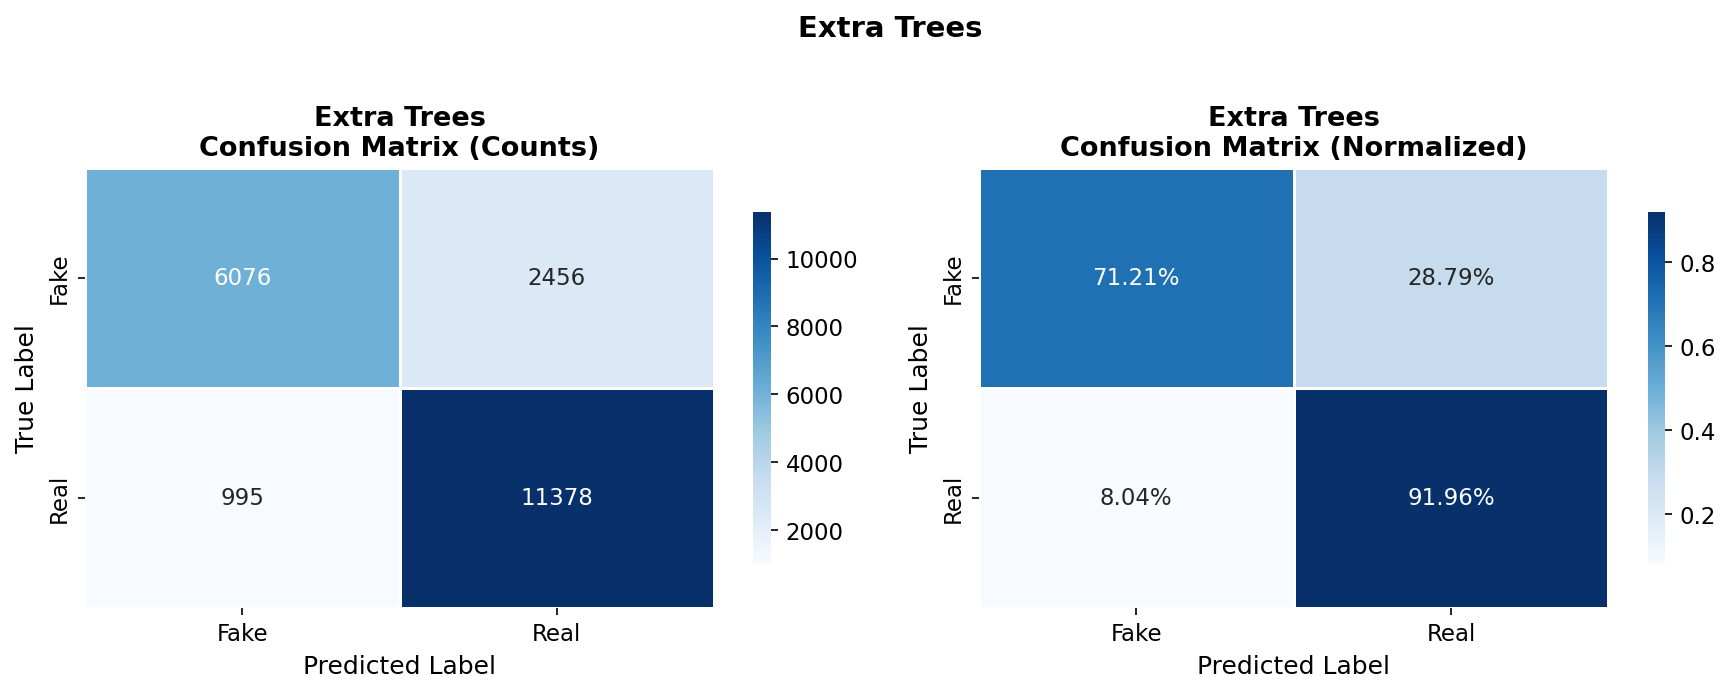

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

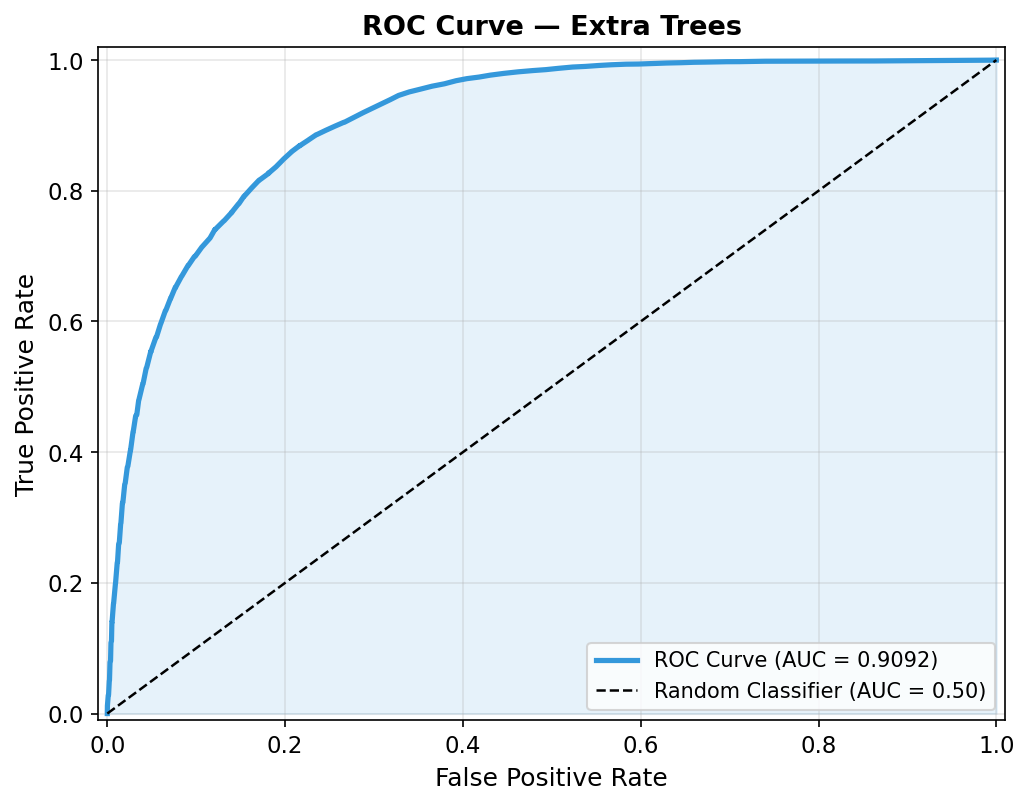

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

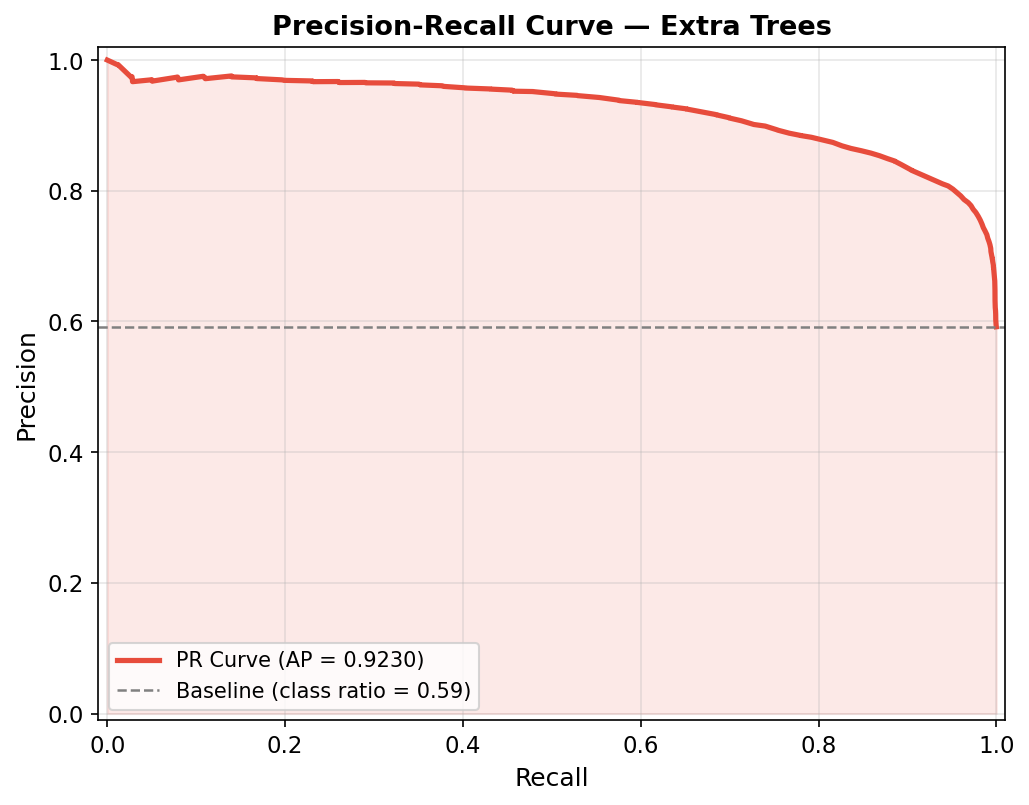

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Training Convergence: Accuracy vs n_estimators

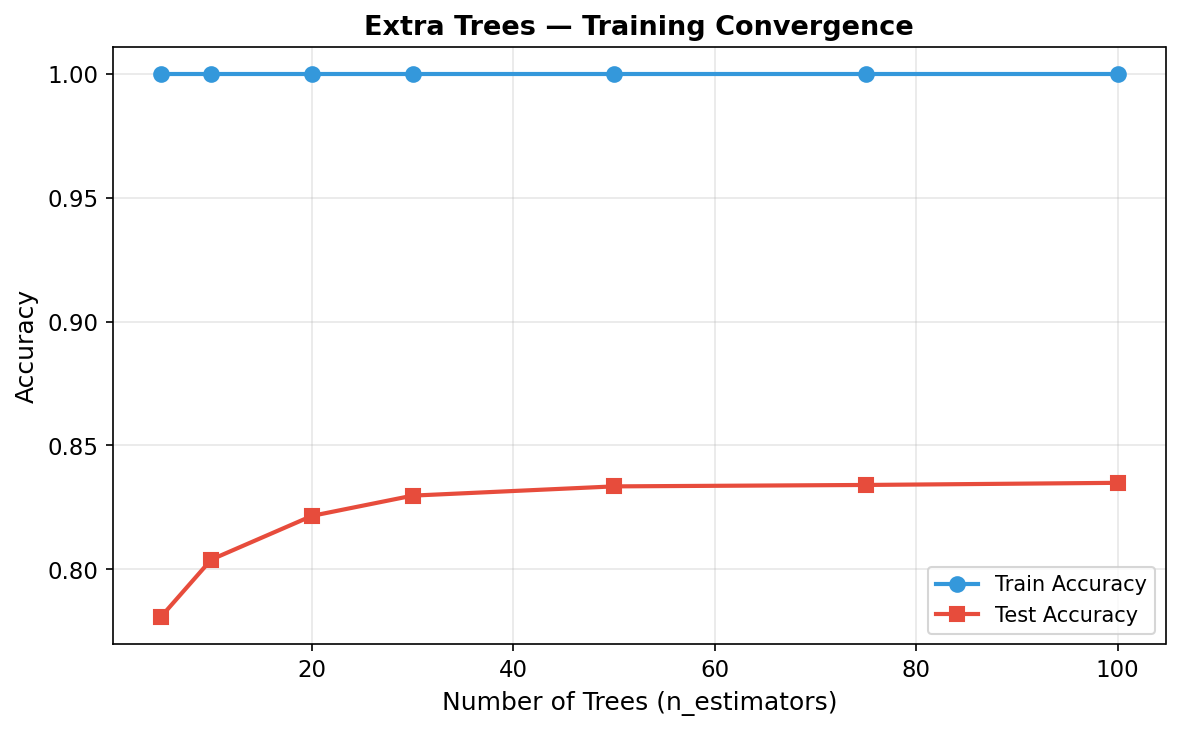

In [8]:
n_list = [5, 10, 20, 30, 50, 75, 100]
tr_accs, te_accs = [], []
for n in n_list:
    m = ExtraTreesClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    m.fit(X_tr, y_train)
    tr_accs.append(accuracy_score(y_train, m.predict(X_tr)))
    te_accs.append(accuracy_score(y_test, m.predict(X_te)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(n_list, tr_accs, 'o-', color='#3498db', lw=2, ms=7, label='Train Accuracy')
ax.plot(n_list, te_accs, 's-', color='#e74c3c', lw=2, ms=7, label='Test Accuracy')
ax.set_xlabel('Number of Trees (n_estimators)')
ax.set_ylabel('Accuracy')
ax.set_title('Extra Trees — Training Convergence')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'extra_trees_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

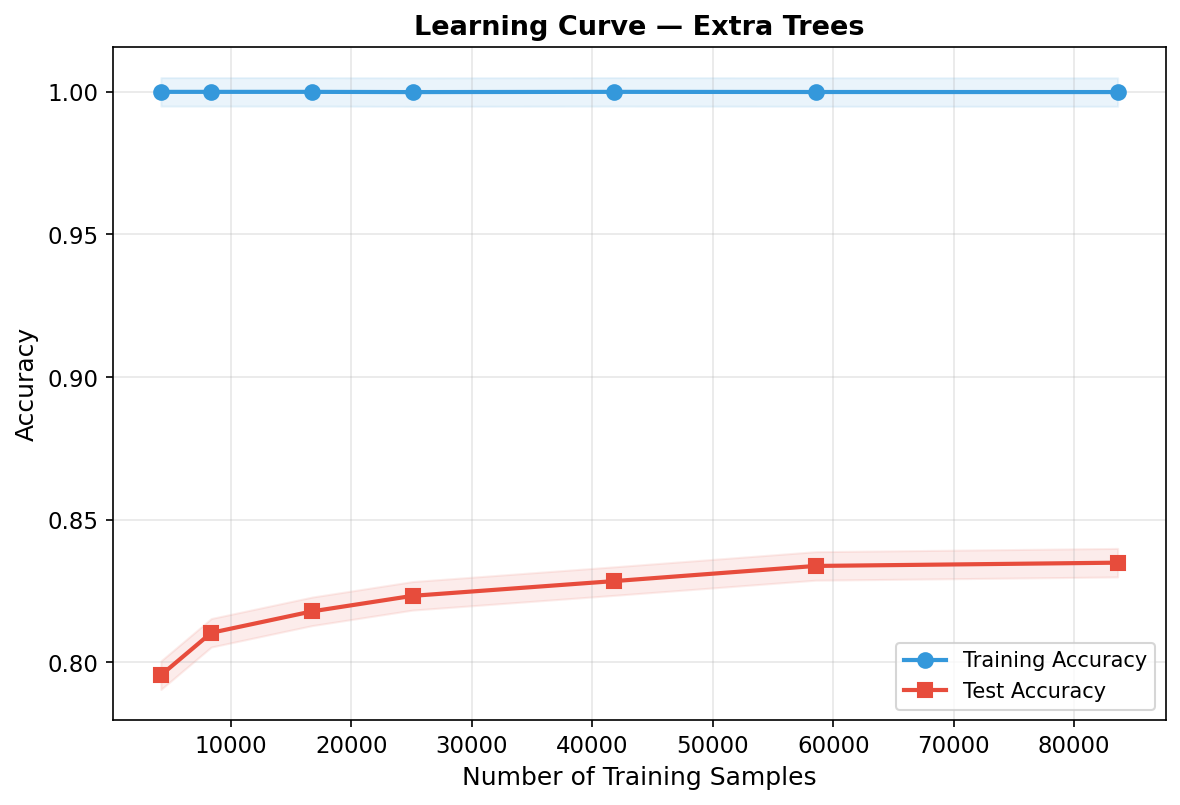

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [1.0,
  1.0,
  1.0,
  0.9999202678998564,
  1.0,
  0.9999487451094292,
  0.9999282433983927],
 [0.7954556326237742,
  0.8103324563501555,
  0.8178426213824443,
  0.8232958622339154,
  0.8284620904089931,
  0.8337718249222674,
  0.8349198756278402])

In [9]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)

## Top Feature Importances

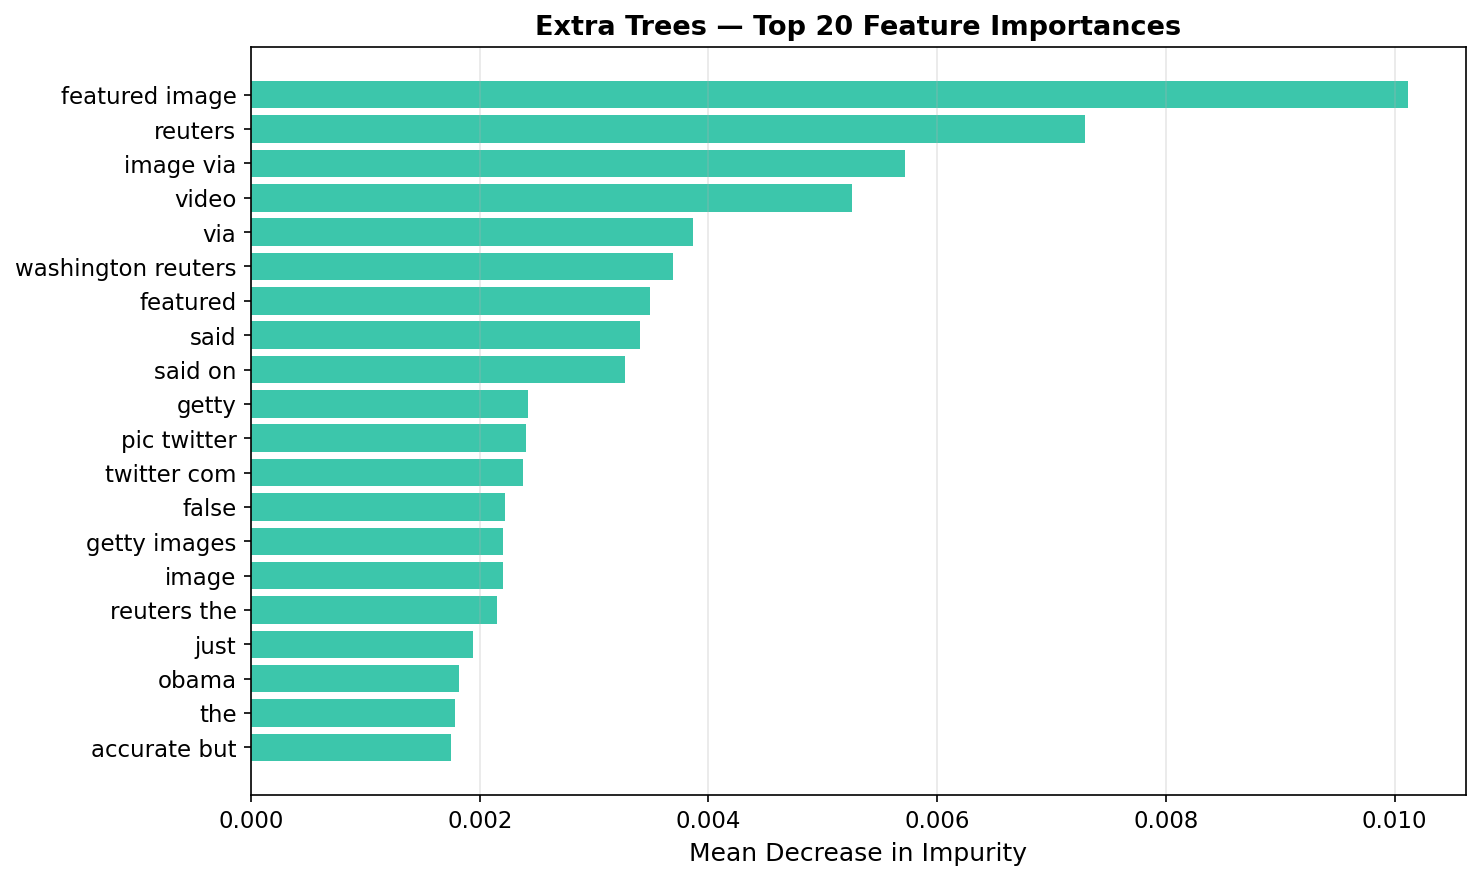

In [10]:
feat_names = np.array(tfidf.get_feature_names_out())
importances = model.feature_importances_
top_idx = np.argsort(importances)[-20:][::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feat_names[top_idx][::-1], importances[top_idx][::-1], color='#1abc9c', alpha=0.85)
ax.set_xlabel('Mean Decrease in Impurity')
ax.set_title('Extra Trees — Top 20 Feature Importances')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'extra_trees_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()